In [26]:
import matplotlib.pyplot as plt
import numpy as np
import importlib
from astropy.io import fits

# import custom functions
import bilinear_interpolation
import cube_decube
import read_fits
import support
import spectral_diff_interpolation

# reload custom function after every cell run
importlib.reload(bilinear_interpolation)
importlib.reload(cube_decube)
importlib.reload(read_fits)
importlib.reload(support)
importlib.reload(spectral_diff_interpolation)

<module 'spectral_diff_interpolation' from '/home/stefan/files/Projects/Licenta/src/src/spectral_diff_interpolation.py'>

In [27]:
interp_path = '../assets/HS-L0-FE-025D-05-01_1C_de2.fits'
detector_layout = '../assets/CRS-HERA-SW101-HyperScout-H-detector-per-pixel-central-wavelength-map.fits'
mars = '../assets/HS-L0-FE-025D-05-01_1C.fits'

In [28]:
with fits.open(interp_path) as hdul:
    inter_cube_data = np.stack([hdu.data for hdu in hdul[1:]], axis=-1)
    wl = np.array([hdu.header["WAVELEN"] for hdu in hdul[1:]])

hyp_img, wl_layout = read_fits.read(
    mars,
    detector_layout
)

In [29]:
hyp_cube = cube_decube.cube(
    hyp_img,
    wl_layout
)

In [30]:
reduced = support.reduce_interp(inter_cube_data)

In [31]:
reduced_full = cube_decube.decube(reduced, wl_layout)

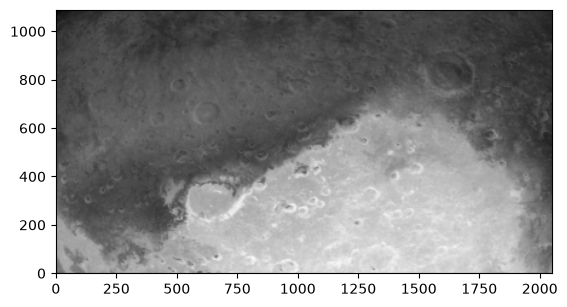

In [32]:
plt.imshow(reduced_full, cmap = 'gray', origin = 'lower')

In [33]:
diff_err = hyp_img[:1088, :2048] - reduced_full[:1088, :2048]

In [34]:
med_ae = np.median(np.abs(diff_err))

In [35]:
rmse = np.sqrt(np.mean((med_ae) ** 2))

In [36]:
print(f'Median Absolute Error = {med_ae * 100} % \nRMSE = {rmse * 100} %')

Median Absolute Error = 22.929184643161733 % 
RMSE = 22.929184643161733 %


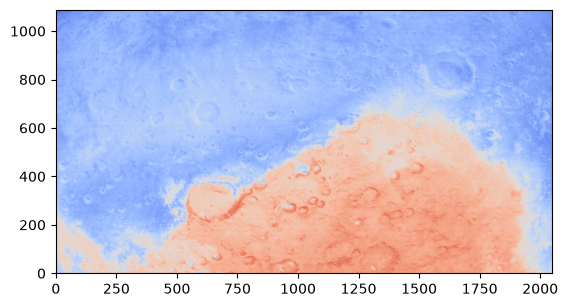

In [37]:
plt.imshow(diff_err, cmap = 'coolwarm', origin = 'lower', vmax = np.max(diff_err), vmin = np.min(diff_err))
plt.show()

In [38]:
zero_count = (diff_err == 0).sum()

In [39]:
print(zero_count)

0
